# Strategy Identification

In this notebook we'll try to identify a methodology to build the primary strategy.

In [38]:
from pathlib import Path
import pandas as pd

def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "data/crypto_dataset_pipeline/crypto_dataset.py").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")

ROOT = find_project_root()
DATASETS_DIR = ROOT / "data/crypto_dataset_pipeline/data/datasets"

In [39]:
volume_100 = pd.read_parquet(DATASETS_DIR / "6a915d3a25d574ce/volume.parquet")

In [40]:
def set_datetime_index(df):
    return df.set_index(
        pd.to_datetime(df["bar_end_us"], unit="us", utc=True)
    ).sort_index().rename_axis("datetime")

df = set_datetime_index(volume_100)
df = df[~df.index.duplicated(keep='first')]

## Features identification

We'll try to identify the candidate features that can form a primary strategy

In [41]:
# Calculate percentage of missing values
null_pct = df.isna().mean() * 100

# Identify columns with more than 1% missing values
cols_to_drop = null_pct[null_pct > 1]

# Display columns to be removed
print(cols_to_drop.sort_values(ascending=False).to_string())

# Remove columns
df = df.drop(columns=cols_to_drop.index)

print(f"\nRemoved {len(cols_to_drop)} columns.")
print(f"Remaining columns: {df.shape[1]}")

etf_btc_net_flow_total_usd                             100.000000
etf_btc_net_flow_total_usd_z60                         100.000000
etf_btc_net_flow_total_usd_economic_age_d              100.000000
etf_btc_net_flow_total_usd_age_s                       100.000000
etf_btc_sum_reported_funds_usd                         100.000000
etf_btc_n_funds_reported                               100.000000
etf_btc_sum_reported_funds_usd_economic_age_d          100.000000
etf_btc_sum_reported_funds_usd_age_s                   100.000000
etf_btc_n_funds_reported_economic_age_d                100.000000
etf_eth_net_flow_total_usd                             100.000000
etf_eth_net_flow_total_usd_age_s                       100.000000
etf_btc_n_funds_reported_age_s                         100.000000
etf_eth_net_flow_total_usd_economic_age_d              100.000000
etf_eth_sum_reported_funds_usd_age_s                   100.000000
etf_eth_sum_reported_funds_usd                         100.000000
etf_eth_ne

TOP MOST CORRELATED FEATURE PAIRS


,Feature 1,Feature 2,Pearson,Absolute correlation
2715,rvol_1d,rvol_ann_1d,1.0000,1.0000
113,last_trade_ts_us,decision_time_us,1.0000,1.0000
812,n_trades,n_messages,1.0000,1.0000
4486,kyle_n_trades_tick,kyle_n_trades_aggr,1.0000,1.0000
4489,kyle_n_trades_tick,hasbrouck_n_trades_tick,1.0000,1.0000
4492,kyle_n_trades_tick,hasbrouck_n_trades_aggr,1.0000,1.0000
4621,kyle_n_trades_aggr,hasbrouck_n_trades_tick,1.0000,1.0000
4624,kyle_n_trades_aggr,hasbrouck_n_trades_aggr,1.0000,1.0000
4747,hasbrouck_n_trades_tick,hasbrouck_n_trades_aggr,1.0000,1.0000
2484,rvol_1h,rvol_ann_1h,1.0000,1.0000


TOP LEAST CORRELATED FEATURE PAIRS


,Feature 1,Feature 2,Pearson,Absolute correlation
1479,ret_5min_ref_age_s,ret_30d_ref_age_s,0.0000,0.0000
385,high,sadf_w200_tau30_p1_c,0.0000,0.0000
1550,ret_5min_ref_age_s,premium_raw_coinbase_eth_1d_coverage,-0.0000,0.0000
387,high,cadf_q95_w200_tau30_p1_c,0.0000,0.0000
2536,rvol_1h,sadf_n_starts_w200_tau30_p1_c,-0.0000,0.0000
2613,rvol_ann_1h,sadf_n_starts_w200_tau30_p1_c,-0.0000,0.0000
2656,rv_1d,aggr_imbalance_volume,-0.0000,0.0000
1473,ret_5min_ref_age_s,ret_4h_ref_age_s,-0.0000,0.0000
1652,ret_1h_ref_age_s,ret_1d_ref_age_s,-0.0000,0.0000
1545,ret_5min_ref_age_s,premium_raw_coinbase_btc_1d_coverage,0.0000,0.0000


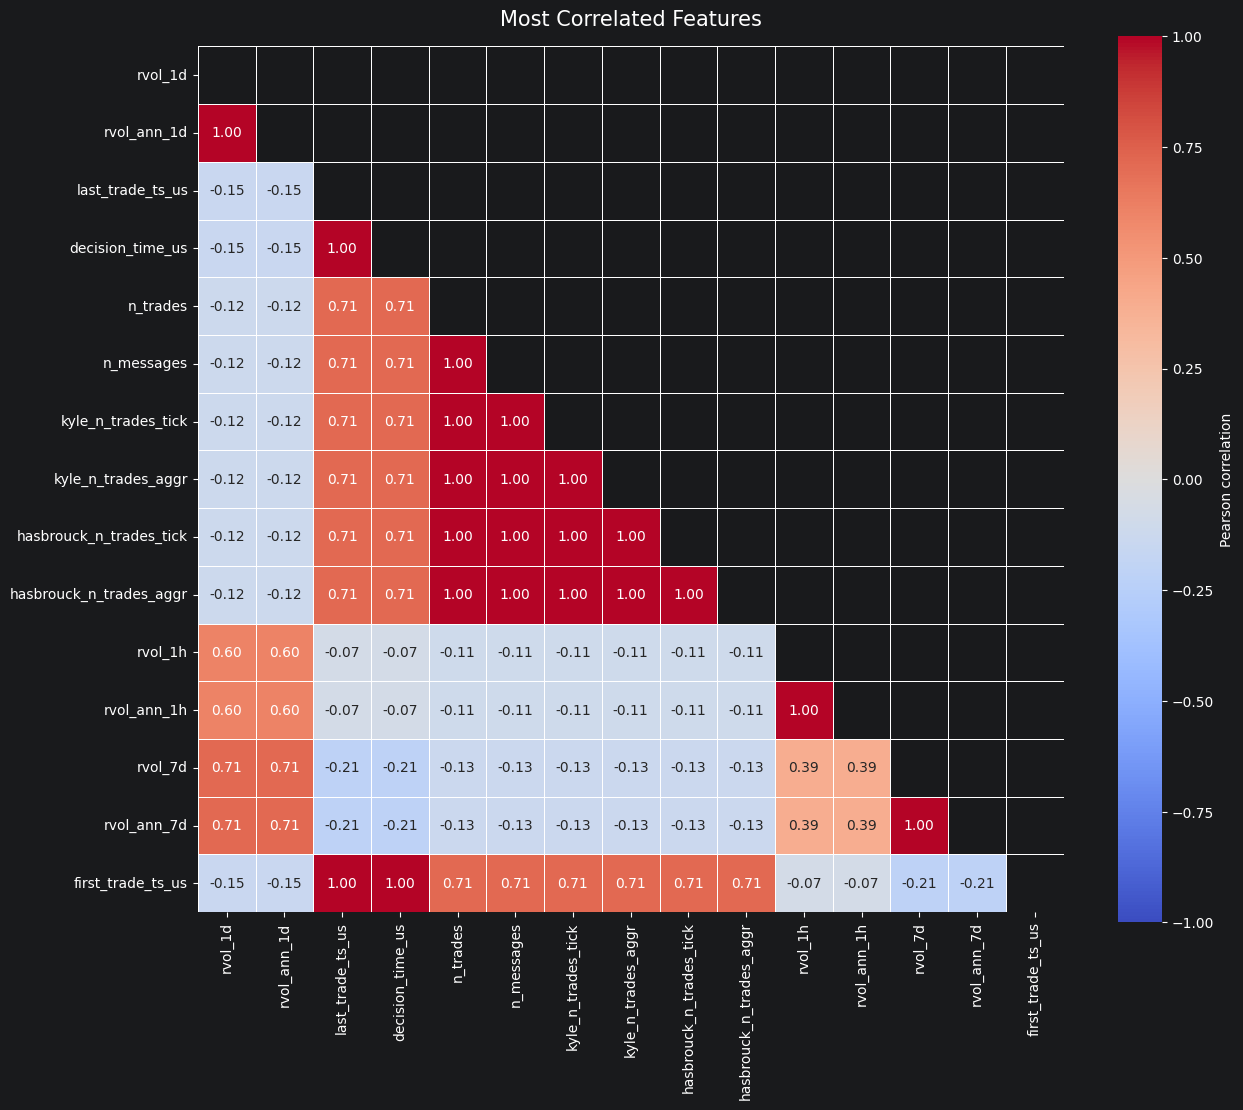

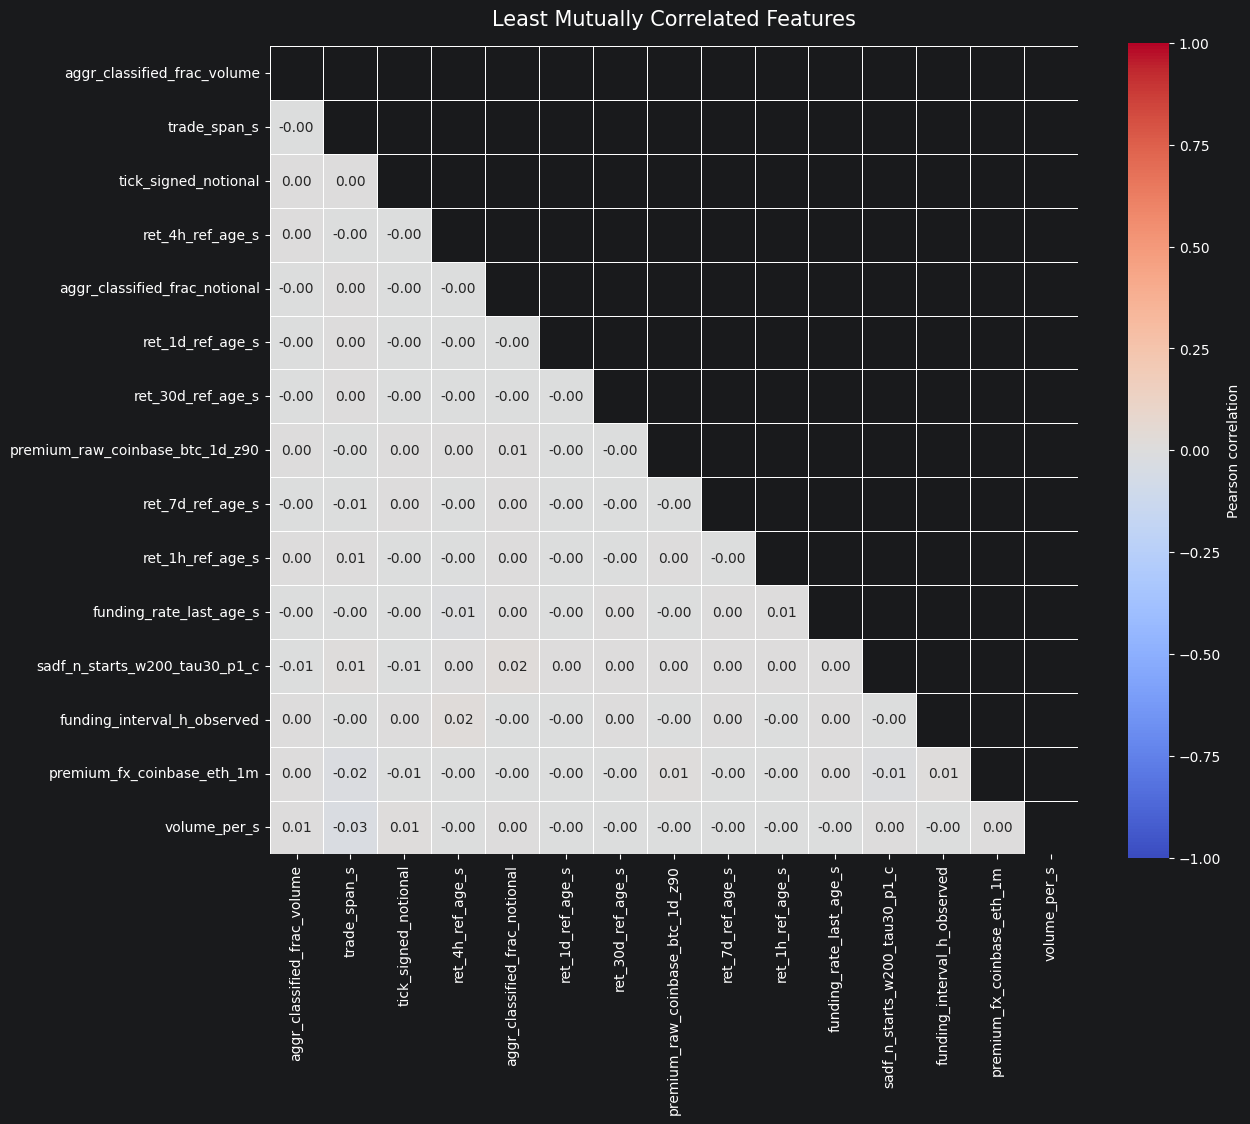

In [42]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

N_FEATURES = 15
N_PAIRS = 30

# 1. Prepare numeric features
numeric_df = df.select_dtypes(include="number")
numeric_df = numeric_df.loc[:, numeric_df.nunique() > 1]

metadata_cols = [
    "bar_seq", "bar_start_us", "bar_end_us",
    "bar_available_us", "first_trade_id", "last_trade_id"
]

numeric_df = numeric_df.drop(columns=metadata_cols, errors="ignore")

# 2. Pearson correlation
corr = numeric_df.corr(method="pearson", min_periods=100)

# 3. Extract unique feature pairs
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)

pairs = corr.where(mask).stack().reset_index()
pairs.columns = ["Feature 1", "Feature 2", "Pearson"]

pairs["Absolute correlation"] = pairs["Pearson"].abs()

# 4. Strongest and weakest correlations
strongest = pairs.nlargest(N_PAIRS, "Absolute correlation")
weakest = pairs.nsmallest(N_PAIRS, "Absolute correlation")

print("TOP MOST CORRELATED FEATURE PAIRS")
display(strongest.style.format({
    "Pearson": "{:.4f}",
    "Absolute correlation": "{:.4f}"
}))

print("TOP LEAST CORRELATED FEATURE PAIRS")
display(weakest.style.format({
    "Pearson": "{:.4f}",
    "Absolute correlation": "{:.4f}"
}))


# 5. Select most correlated features
high_features = pd.unique(
    strongest[["Feature 1", "Feature 2"]].to_numpy().ravel()
).tolist()[:N_FEATURES]


# 6. Select features with LOW mutual correlation
abs_corr = corr.abs().fillna(1.0).copy()
np.fill_diagonal(abs_corr.values, np.nan)

mean_abs_corr = abs_corr.mean(axis=1)

# Start with the feature least correlated to all others
low_features = [mean_abs_corr.idxmin()]

# Greedily add features minimizing correlation to selected ones
while len(low_features) < min(N_FEATURES, len(corr)):
    candidates = [
        c for c in corr.columns
        if c not in low_features
    ]

    next_feature = min(
        candidates,
        key=lambda c: (
            abs_corr.loc[c, low_features].max(),
            abs_corr.loc[c, low_features].mean()
        )
    )

    low_features.append(next_feature)


# 7. Heatmap function
def plot_correlation_heatmap(features, title):
    subset = corr.loc[features, features]

    # Hide diagonal and upper triangle
    mask = np.triu(np.ones(subset.shape, dtype=bool))

    plt.figure(figsize=(13, 11))

    sns.heatmap(
        subset,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar_kws={"label": "Pearson correlation"}
    )

    plt.title(title, fontsize=15, pad=15)
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


# 8. Plot both heatmaps
plot_correlation_heatmap(
    high_features,
    "Most Correlated Features"
)

plot_correlation_heatmap(
    low_features,
    "Least Mutually Correlated Features"
)

## Trend Scanning

We have few candidates: t-value, and returns, we try to see the volution of correlation with features with these values.
We want to see if the correlation is stronger if we test just cusum events

In [43]:
from mlfinpy.labeling import trend_scanning_labels

tr_scan_labels = trend_scanning_labels(
    price_series=df['close'],
    t_events=df['close'].index,
    look_forward_window=20,
    min_sample_length=10
)



/home/octa/miniconda3/envs/disertatie/lib/python3.11/site-packages/mlfinpy/labeling/trend_scanning.py:83: RuntimeWarning: divide by zero encountered in divide
  t_beta_1 = (b_mean_[1] / np.sqrt(b_std_[1, 1]))[0]


In [44]:
tr_scan_labels

,t1,t_value,ret,bin
datetime,,,,
2021-09-01 00:05:04.669000+00:00,2021-09-01 01:40:22.919000+00:00,-4.423767,-0.009888,-1.0
2021-09-01 00:10:25.155000+00:00,2021-09-01 01:50:52.291000+00:00,-2.051034,-0.004201,-1.0
2021-09-01 00:18:39.021000+00:00,2021-09-01 04:07:57.524000+00:00,1.660419,0.000681,1.0
2021-09-01 00:29:49.698000+00:00,2021-09-01 04:14:54.382000+00:00,3.027314,0.005181,1.0
2021-09-01 00:46:23.453000+00:00,2021-09-01 04:24:15.434000+00:00,4.958615,0.013354,1.0
...,...,...,...,...
2026-08-31 19:50:04.172370+00:00,NaT,NaN,NaN,NaN
2026-08-31 20:31:42.967917+00:00,NaT,NaN,NaN,NaN
2026-08-31 21:13:59.015174+00:00,NaT,NaN,NaN,NaN


In [45]:
df = pd.concat([df, tr_scan_labels], axis=1)

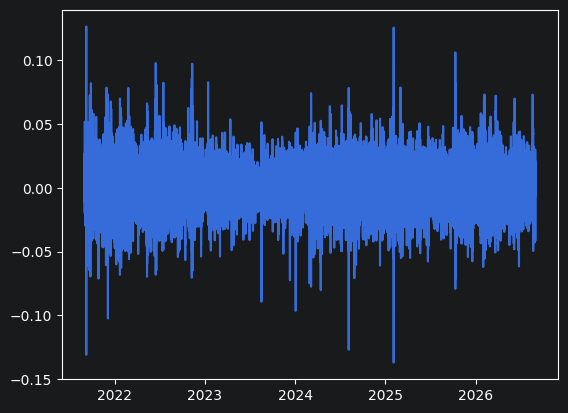

In [46]:
plt.plot(df['ret'])

In [47]:
print(list(df.columns))

['bar_id', 'series_id', 'bar_type', 'bar_seq', 'segment_id', 'bar_start_us', 'bar_end_us', 'first_trade_ts_us', 'last_trade_ts_us', 'first_trade_id', 'last_trade_id', 'open', 'high', 'low', 'close', 'volume', 'notional_usdt', 'n_trades', 'n_messages', 'threshold_frozen', 'complete', 'bar_status', 'bar_available_us', 'decision_time_us', 'bar_provenance', 'bar_start', 'bar_end', 'bar_available', 'decision_time', 'ret_bars_1', 'ret_bars_5', 'ret_bars_20', 'ret_5min', 'ret_5min_ref_age_s', 'ret_1h', 'ret_1h_ref_age_s', 'ret_4h', 'ret_4h_ref_age_s', 'ret_1d', 'ret_1d_ref_age_s', 'ret_7d', 'ret_7d_ref_age_s', 'ret_30d', 'ret_30d_ref_age_s', 'rv_1h', 'rvol_1h', 'rvol_ann_1h', 'rv_1d', 'rvol_1d', 'rvol_ann_1d', 'rv_7d', 'rvol_7d', 'rvol_ann_7d', 'rv_bars_20', 'rv_bars_100', 'bar_duration_s', 'trade_span_s', 'avg_trade_size', 'trade_intensity_per_s', 'volume_per_s', 'notional_per_s', 'aggr_buy_volume', 'aggr_sell_volume', 'aggr_signed_volume', 'aggr_classified_frac_volume', 'aggr_imbalance_volu

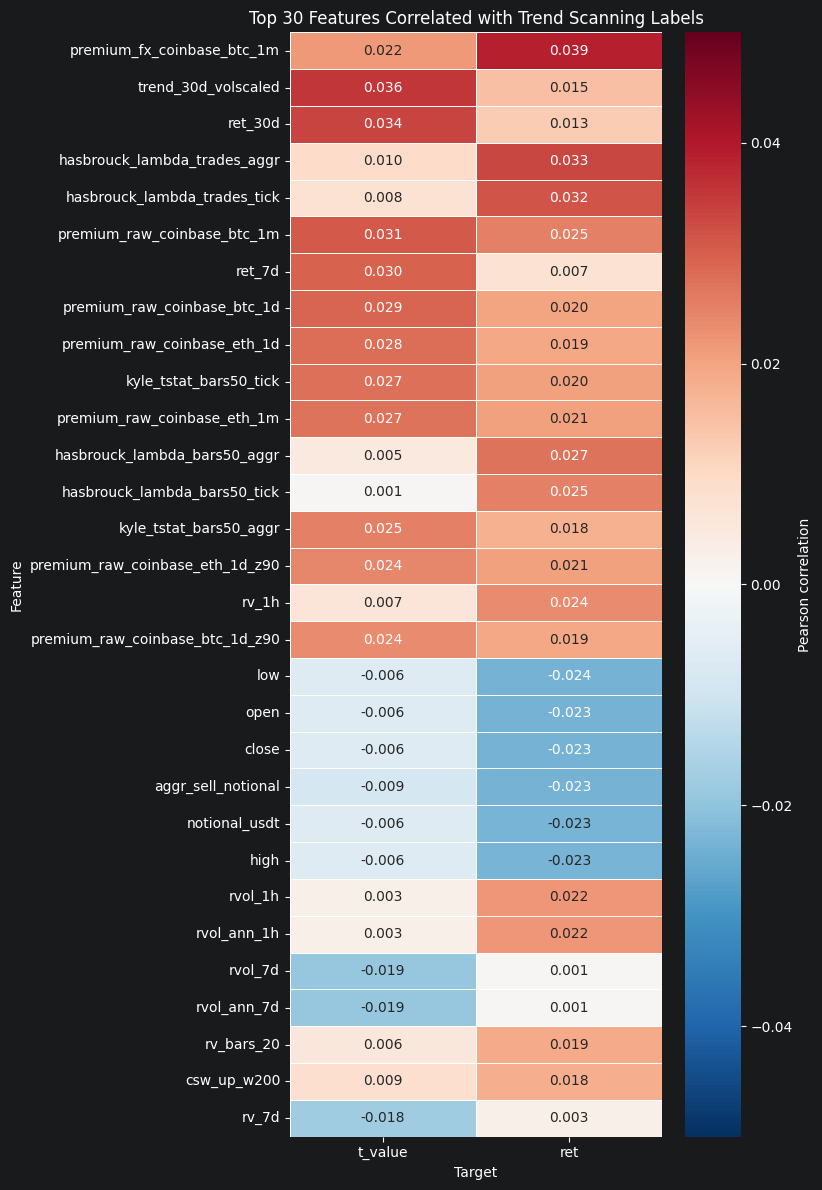

,t_value,ret
premium_fx_coinbase_btc_1m,0.0217,0.0387
trend_30d_volscaled,0.0356,0.0150
ret_30d,0.0338,0.0126
hasbrouck_lambda_trades_aggr,0.0096,0.0333
hasbrouck_lambda_trades_tick,0.0076,0.0315
premium_raw_coinbase_btc_1m,0.0307,0.0253
ret_7d,0.0296,0.0075
premium_raw_coinbase_btc_1d,0.0290,0.0199
premium_raw_coinbase_eth_1d,0.0281,0.0195
kyle_tstat_bars50_tick,0.0274,0.0204


In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

targets = ["t_value", "ret"]

# Excludem metadata, identificatori și coloane care produc leakage
exclude_cols = [
    "bar_id", "series_id", "bar_seq", "segment_id",
    "bar_start_us", "bar_end_us",
    "first_trade_ts_us", "last_trade_ts_us",
    "first_trade_id", "last_trade_id",
    "bar_available_us", "decision_time_us",
    "threshold_frozen", "complete",
    "t1", "bin", "t_value", "ret"
]

# Păstrăm doar coloanele numerice
numeric_df = df.select_dtypes(include="number").copy()
numeric_df = numeric_df.replace([np.inf, -np.inf], np.nan)

feature_cols = [
    col for col in numeric_df.columns
    if col not in exclude_cols
    and numeric_df[col].nunique(dropna=True) > 1
]

features = numeric_df[feature_cols]

# Corelații Pearson cu ambele ținte
corr = pd.DataFrame({
    target: features.corrwith(numeric_df[target], method="pearson")
    for target in targets
})

# Excludem corelațiile bazate pe prea puține observații
min_obs = max(100, int(len(df) * 0.05))

for target in targets:
    valid_counts = features.notna().mul(
        numeric_df[target].notna(), axis=0
    ).sum()

    corr.loc[valid_counts < min_obs, target] = np.nan

# Top 30 după cea mai mare corelație absolută cu oricare țintă
top_features = (
    corr.abs()
    .max(axis=1)
    .nlargest(30)
    .index
)

top_corr = corr.loc[top_features]

# Heatmap
plt.figure(figsize=(8, 12))

sns.heatmap(
    top_corr,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    vmin=-max(0.05, top_corr.abs().max().max()),
    vmax=max(0.05, top_corr.abs().max().max()),
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title("Top 30 Features Correlated with Trend Scanning Labels")
plt.xlabel("Target")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(top_corr.round(4))

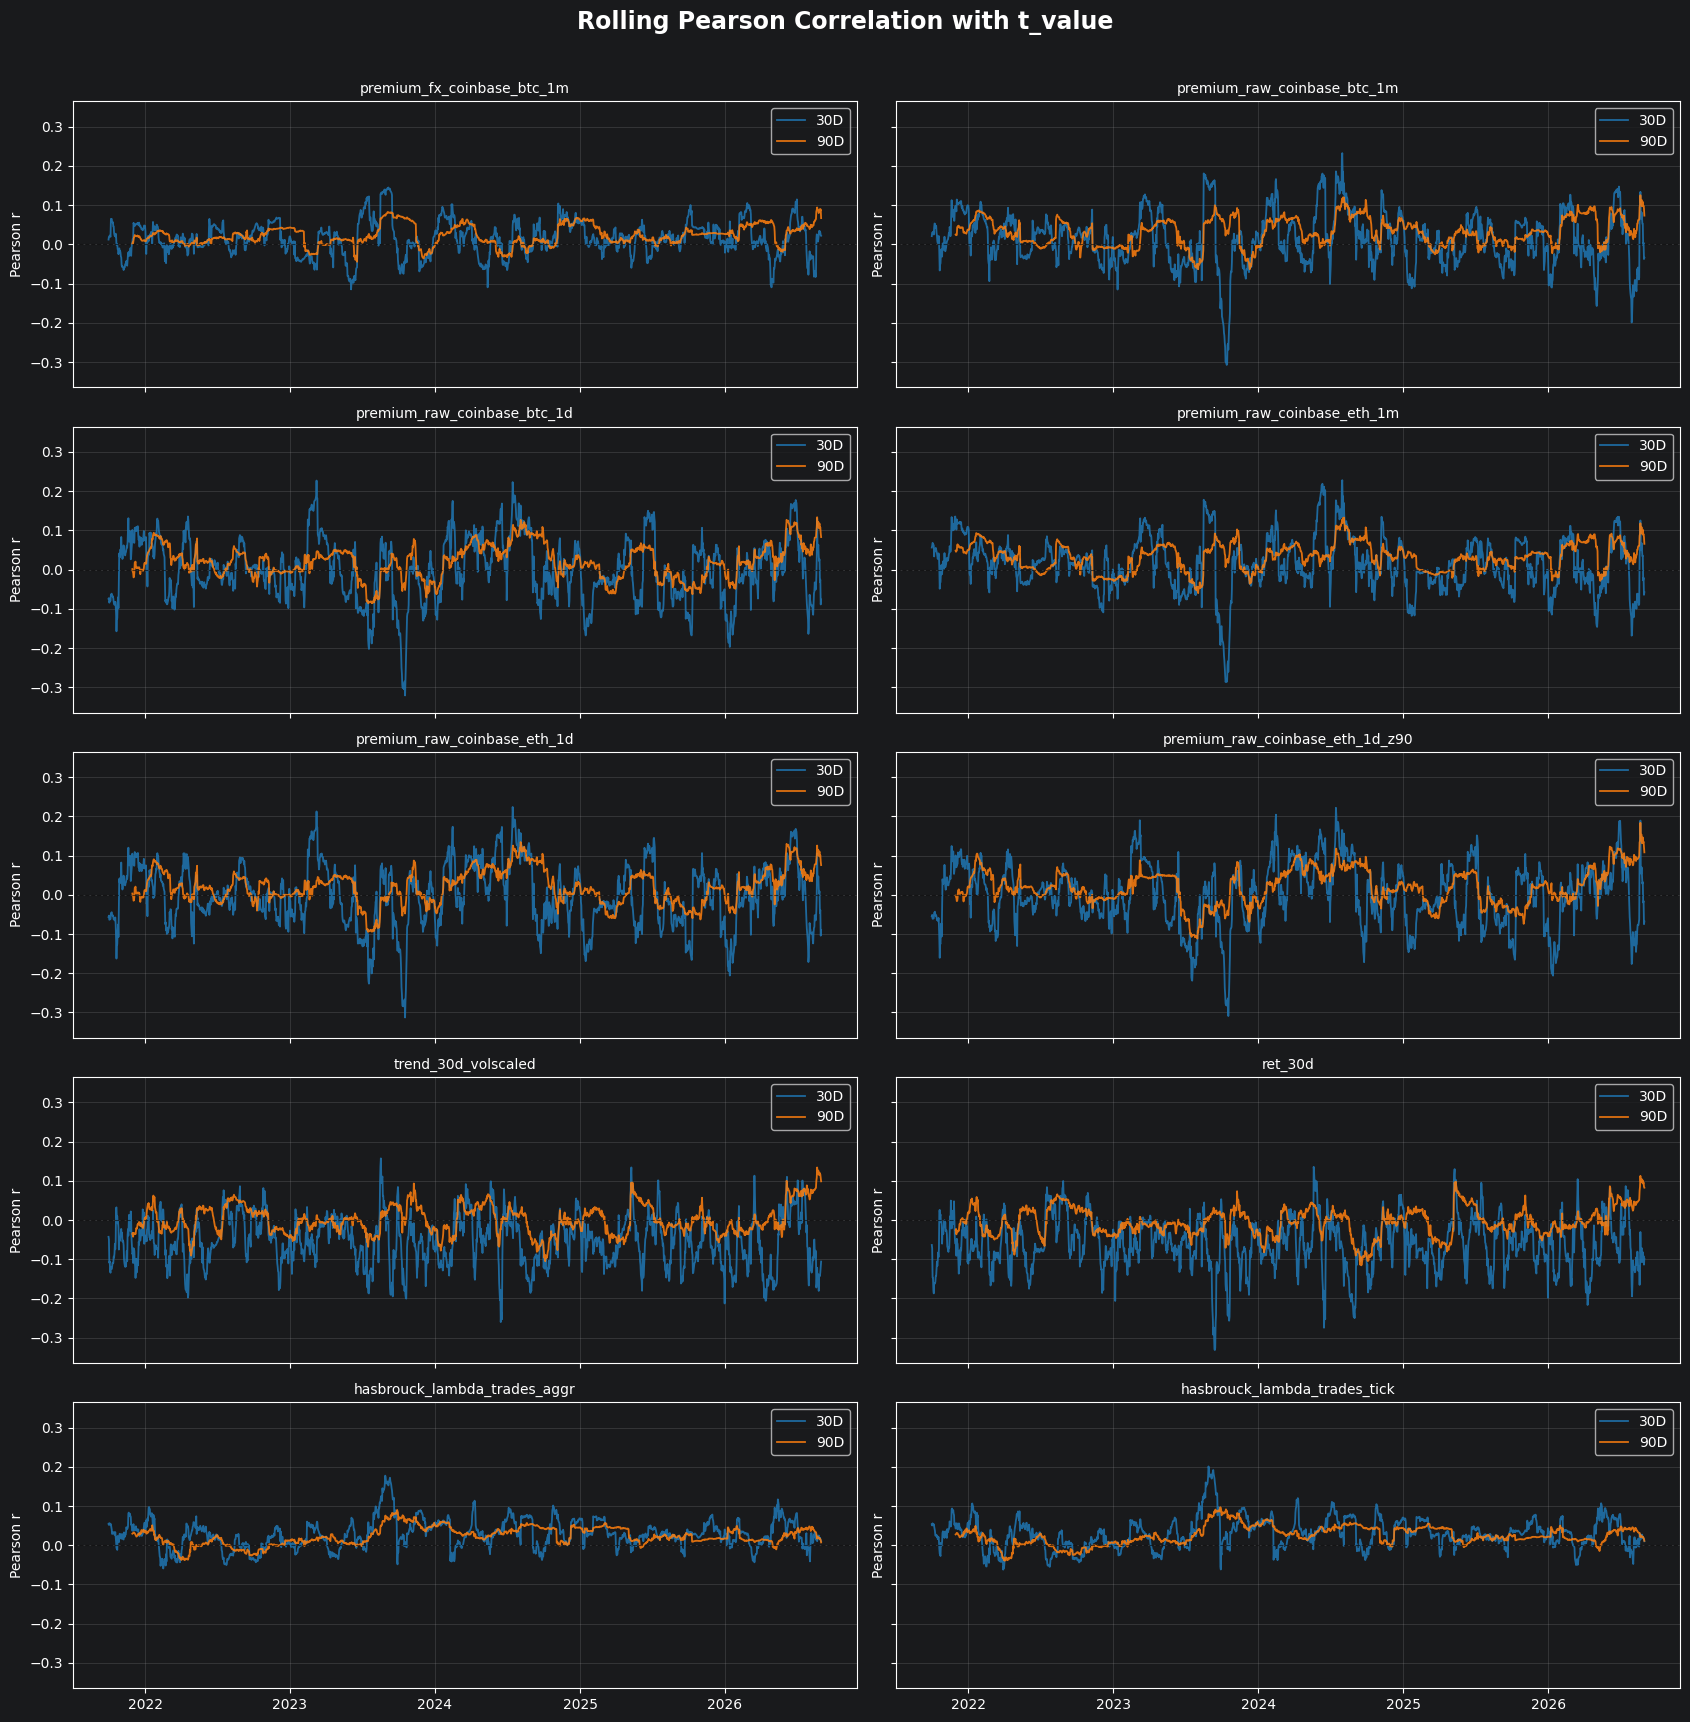

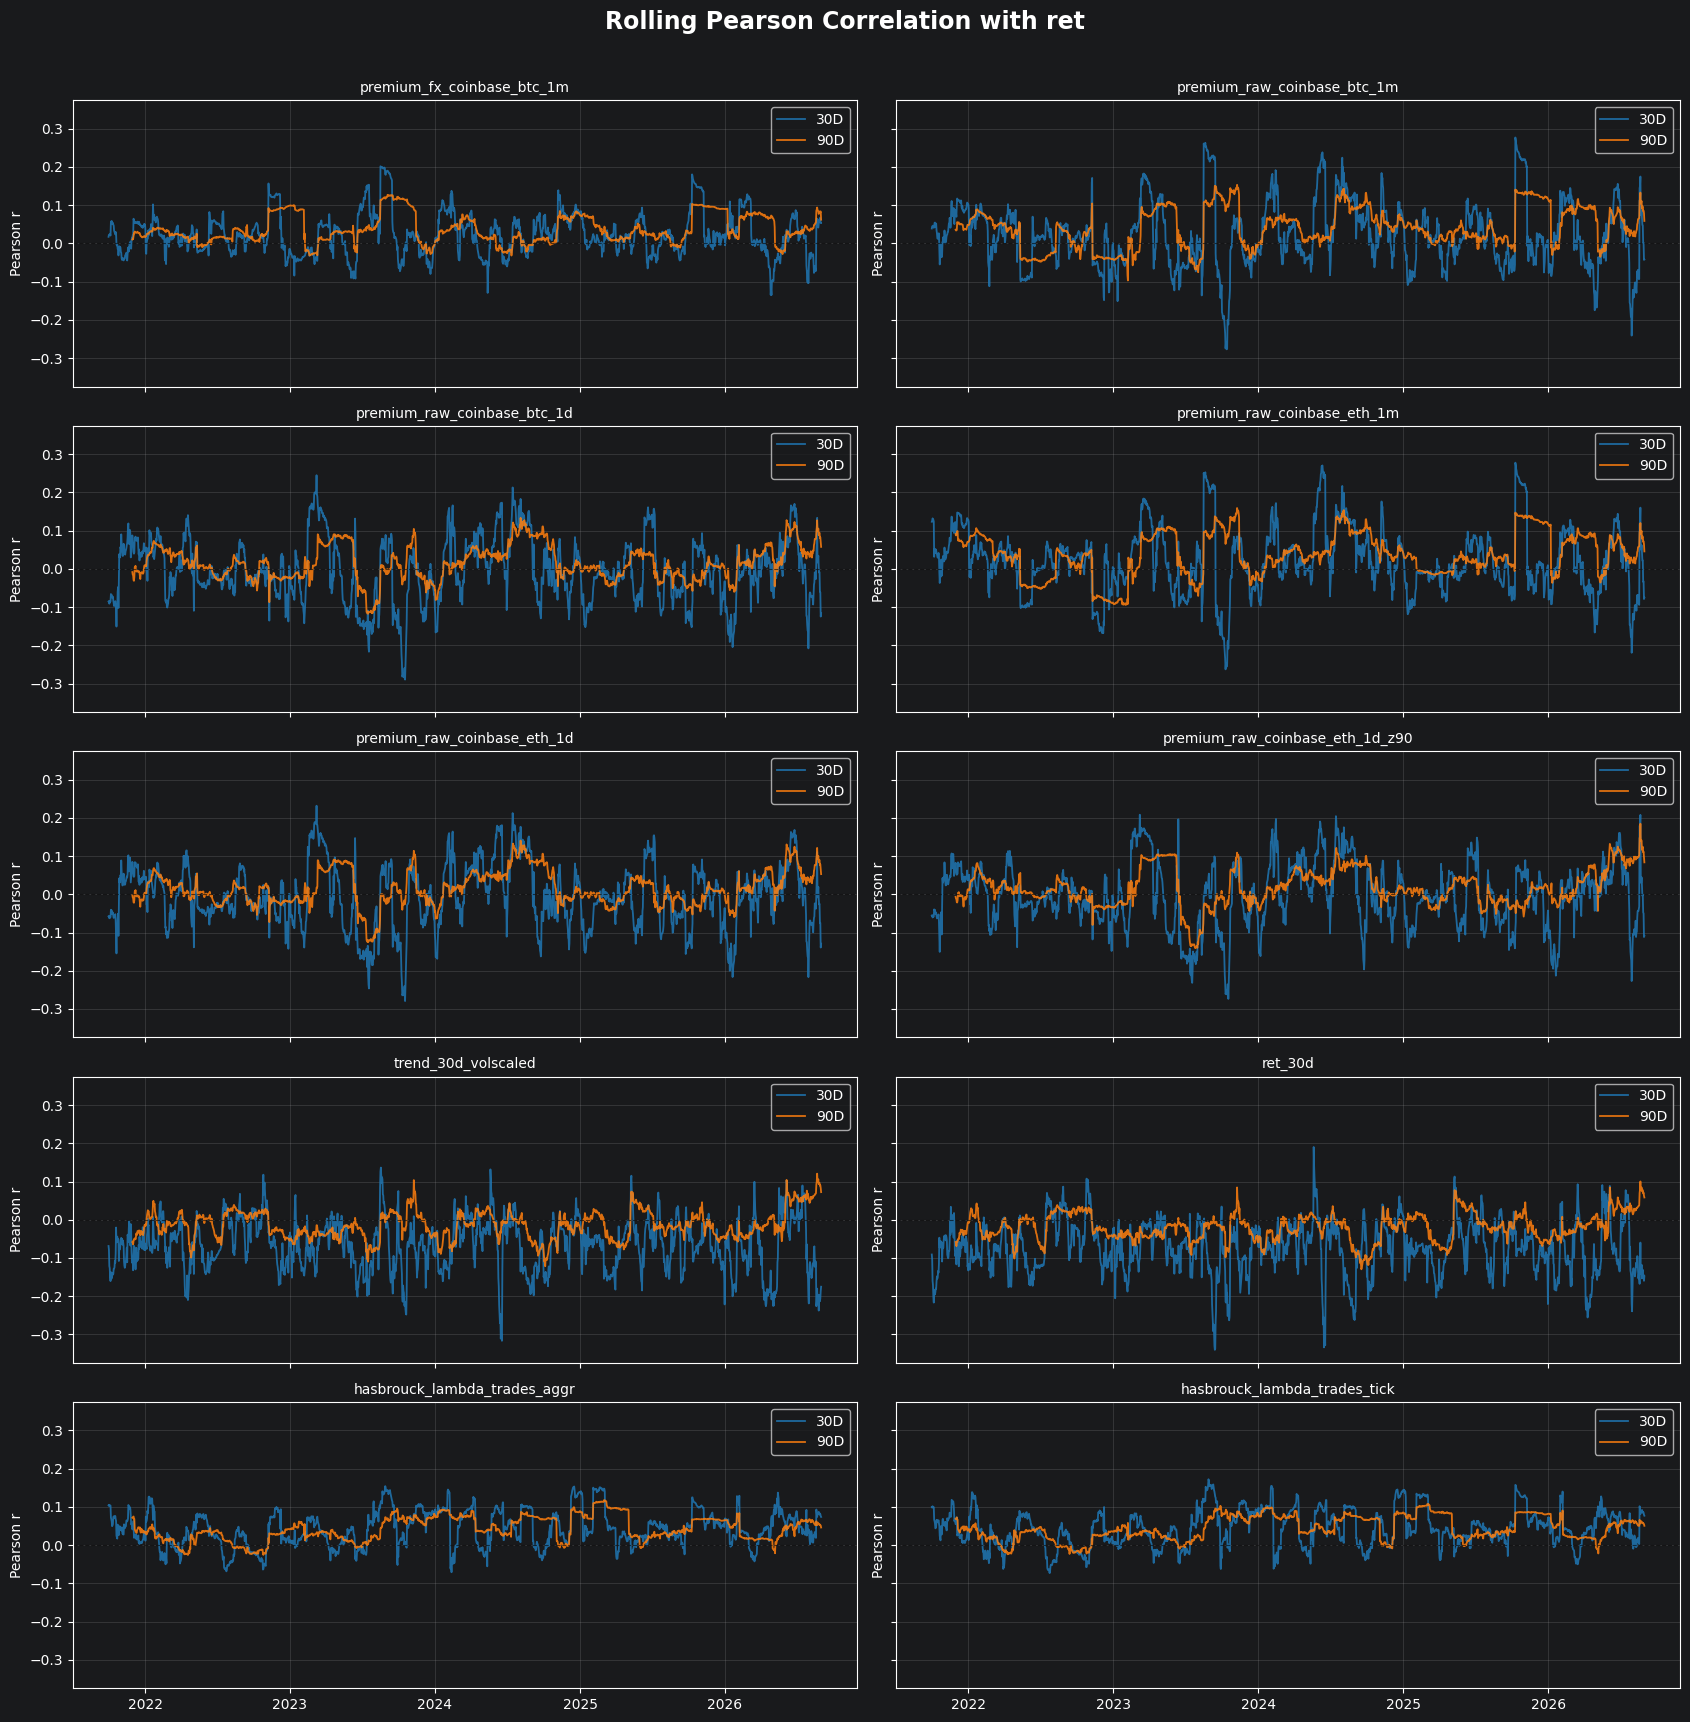

,feature,target,window,mean_r,median_r,min_r,max_r,positive_pct,latest_r,latest_n
38,hasbrouck_lambda_trades_tick,ret,30D,0.0442,0.0406,-0.0731,0.1724,81.2361,0.0770,1608
34,hasbrouck_lambda_trades_aggr,ret,30D,0.0427,0.0391,-0.0708,0.1544,82.0156,0.0738,1608
2,premium_fx_coinbase_btc_1m,ret,30D,0.0230,0.0182,-0.1349,0.2019,65.8129,0.0534,1608
6,premium_raw_coinbase_btc_1m,ret,30D,0.0224,0.0146,-0.2769,0.2772,59.5768,-0.0420,1608
14,premium_raw_coinbase_eth_1m,ret,30D,0.0217,0.0141,-0.2628,0.2778,59.0757,-0.0754,1608
22,premium_raw_coinbase_eth_1d_z90,ret,30D,-0.0031,-0.0031,-0.2735,0.2081,47.9955,-0.1088,1608
10,premium_raw_coinbase_btc_1d,ret,30D,-0.0045,-0.0090,-0.2895,0.2449,45.1559,-0.1166,1608
18,premium_raw_coinbase_eth_1d,ret,30D,-0.0057,-0.0096,-0.2792,0.2316,45.4900,-0.1293,1608
26,trend_30d_volscaled,ret,30D,-0.0659,-0.0620,-0.3167,0.1365,15.7572,-0.1752,1608
30,ret_30d,ret,30D,-0.0729,-0.0720,-0.3403,0.1902,12.4722,-0.1480,1608


In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. FEATURE-URI SELECTATE
# ============================================================

features = [
    "premium_fx_coinbase_btc_1m",
    "premium_raw_coinbase_btc_1m",
    "premium_raw_coinbase_btc_1d",
    "premium_raw_coinbase_eth_1m",
    "premium_raw_coinbase_eth_1d",
    "premium_raw_coinbase_eth_1d_z90",
    "trend_30d_volscaled",
    "ret_30d",
    "hasbrouck_lambda_trades_aggr",
    "hasbrouck_lambda_trades_tick",
]

targets = ["t_value", "ret"]

windows = {
    "30D": 200,   # Minimum 200 observații valide
    "90D": 500,   # Minimum 500 observații valide
}

features = [f for f in features if f in df.columns]

# ============================================================
# 2. PREGĂTIREA DATELOR
# ============================================================

# Folosim momentul de încheiere al barei
if "bar_end" in df.columns:
    timestamps = pd.to_datetime(
        df["bar_end"], utc=True, errors="coerce"
    )
elif "bar_end_us" in df.columns:
    timestamps = pd.to_datetime(
        df["bar_end_us"], unit="us", utc=True, errors="coerce"
    )
elif isinstance(df.index, pd.DatetimeIndex):
    timestamps = pd.to_datetime(df.index, utc=True)
else:
    raise ValueError("Nu există o coloană temporală validă.")

data = df[features + targets].copy()
data.index = pd.DatetimeIndex(timestamps)

# Eliminăm doar rândurile fără timestamp
data = data.loc[data.index.notna()]

# Ordonare cronologică stabilă; păstrăm barele distincte
# care au același timestamp
data = data.sort_index(kind="stable")

data = data.apply(pd.to_numeric, errors="coerce")
data = data.replace([np.inf, -np.inf], np.nan)

# ============================================================
# 3. ROLLING PEARSON CORRELATION
# ============================================================

rolling_corr = {}
rolling_n = {}

start_date = data.index.min()

for feature in features:
    x = data[feature]

    for target in targets:
        y = data[target]

        # Numărăm perechile în care ambele valori există
        valid_pair = (x.notna() & y.notna()).astype(float)

        for window, min_obs in windows.items():

            # Corelație pe barele din ultimele 30/90 zile
            corr = x.rolling(
                window=window,
                min_periods=min_obs
            ).corr(y)

            # Numărul perechilor valide din fiecare fereastră
            n_obs = valid_pair.rolling(
                window=window,
                min_periods=1
            ).sum()

            # Nu afișăm ferestre calendaristice incomplete
            first_full_window = (
                start_date + pd.Timedelta(window)
            )

            corr = corr.where(
                corr.index >= first_full_window
            )

            # Păstrăm ultima estimare din fiecare zi
            corr_daily = corr.resample("D").last()
            n_daily = n_obs.resample("D").last()

            rolling_corr[(feature, target, window)] = corr_daily
            rolling_n[(feature, target, window)] = n_daily

# ============================================================
# 4. GRAFICE — CÂTE UNUL PENTRU FIECARE FEATURE
# ============================================================

for target in targets:

    n_features = len(features)
    n_cols = 2
    n_rows = int(np.ceil(n_features / n_cols))

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(17, 3.4 * n_rows),
        sharex=True,
        sharey=True
    )

    axes = np.array(axes).flatten()

    # Aceeași scală verticală pentru toate feature-urile
    max_abs_corr = max(
        rolling_corr[(f, target, w)].abs().max()
        for f in features
        for w in windows
    )
    ylim = max(0.10, min(1.0, max_abs_corr * 1.1))

    for i, feature in enumerate(features):

        ax = axes[i]

        for window, color in [
            ("30D", "tab:blue"),
            ("90D", "tab:orange")
        ]:

            series = rolling_corr[
                (feature, target, window)
            ]

            ax.plot(
                series.index,
                series.values,
                label=window,
                color=color,
                linewidth=1.3,
                alpha=0.85
            )

        ax.axhline(
            0,
            color="black",
            linestyle="--",
            linewidth=0.8,
            alpha=0.6
        )

        ax.set_title(feature, fontsize=10)
        ax.set_ylabel("Pearson r")
        ax.set_ylim(-ylim, ylim)
        ax.grid(alpha=0.25)
        ax.legend(loc="upper right")

    for ax in axes[n_features:]:
        ax.set_visible(False)

    fig.suptitle(
        f"Rolling Pearson Correlation with {target}",
        fontsize=17,
        fontweight="bold",
        y=1.01
    )

    plt.tight_layout()
    plt.show()

# ============================================================
# 5. STATISTICI DESPRE CORELATII
# ============================================================

results = []

for feature in features:
    for target in targets:
        for window in windows:

            corr = rolling_corr[
                (feature, target, window)
            ]

            n = rolling_n[
                (feature, target, window)
            ]

            valid_corr = corr.dropna()

            if valid_corr.empty:
                continue

            last_date = valid_corr.index[-1]

            results.append({
                "feature": feature,
                "target": target,
                "window": window,
                "mean_r": valid_corr.mean(),
                "median_r": valid_corr.median(),
                "min_r": valid_corr.min(),
                "max_r": valid_corr.max(),
                "positive_pct": (
                    valid_corr.gt(0).mean() * 100
                ),
                "latest_r": valid_corr.iloc[-1],
                "latest_n": int(n.loc[last_date])
            })

summary = pd.DataFrame(results)

display(
    summary.round(4).sort_values(
        ["target", "window", "mean_r"],
        ascending=[True, True, False]
    )
)

## Cusum filter

Now we want to see what impact has cusum filter on these correlations

In [50]:
from mlfinpy.filters import cusum_filter

cusum_events = cusum_filter(
    raw_time_series=df['close'],
    threshold=0.05
)

In [51]:
targets = ["t_value", "ret"]

# Identificăm evenimentele CUSUM
events = pd.Index(cusum_events)

if events.has_duplicates:
    raise ValueError("cusum_events conține timestampuri duplicate.")

cusum_mask = df.index.isin(events)

if cusum_mask.sum() != len(events):
    raise ValueError(
        "Evenimentele nu corespund 1-la-1 barelor din df. "
        "Verifică timestampurile lipsă sau duplicate."
    )

print(f"Total bare: {len(df):,}")
print(f"Evenimente CUSUM: {cusum_mask.sum():,}")
print(f"Non-CUSUM: {(~cusum_mask).sum():,}")
print(f"Procent selectat: {cusum_mask.mean() * 100:.2f}%")

# Excludem metadata și informații despre etichete
exclude_cols = [
    "bar_id", "series_id", "bar_seq", "segment_id",
    "bar_start_us", "bar_end_us",
    "first_trade_ts_us", "last_trade_ts_us",
    "first_trade_id", "last_trade_id",
    "bar_available_us", "decision_time_us",
    "threshold_frozen", "complete",
    "t1", "bin", "t_value", "ret"
]

numeric_df = df.select_dtypes(include="number").copy()
numeric_df = numeric_df.replace([np.inf, -np.inf], np.nan)

feature_cols = [
    c for c in numeric_df.columns
    if c not in exclude_cols
    and numeric_df[c].nunique(dropna=True) > 1
]

def compute_correlations(mask, min_obs=100):
    subset = numeric_df.iloc[np.flatnonzero(mask)]
    features = subset[feature_cols]

    correlations = pd.DataFrame({
        target: features.corrwith(
            subset[target], method="pearson"
        )
        for target in targets
    })

    counts = pd.DataFrame({
        target: features.notna().mul(
            subset[target].notna(), axis=0
        ).sum()
        for target in targets
    })

    correlations = correlations.where(counts >= min_obs)

    return correlations, counts


corr_all, n_all = compute_correlations(
    np.ones(len(df), dtype=bool)
)

corr_cusum, n_cusum = compute_correlations(cusum_mask)

corr_non_cusum, n_non_cusum = compute_correlations(
    ~cusum_mask
)

# Top 30 feature-uri după corelațiile CUSUM
top_features = (
    corr_cusum.abs()
    .max(axis=1)
    .nlargest(30)
    .index
)

Total bare: 182,698
Evenimente CUSUM: 1,661
Non-CUSUM: 181,037
Procent selectat: 0.91%


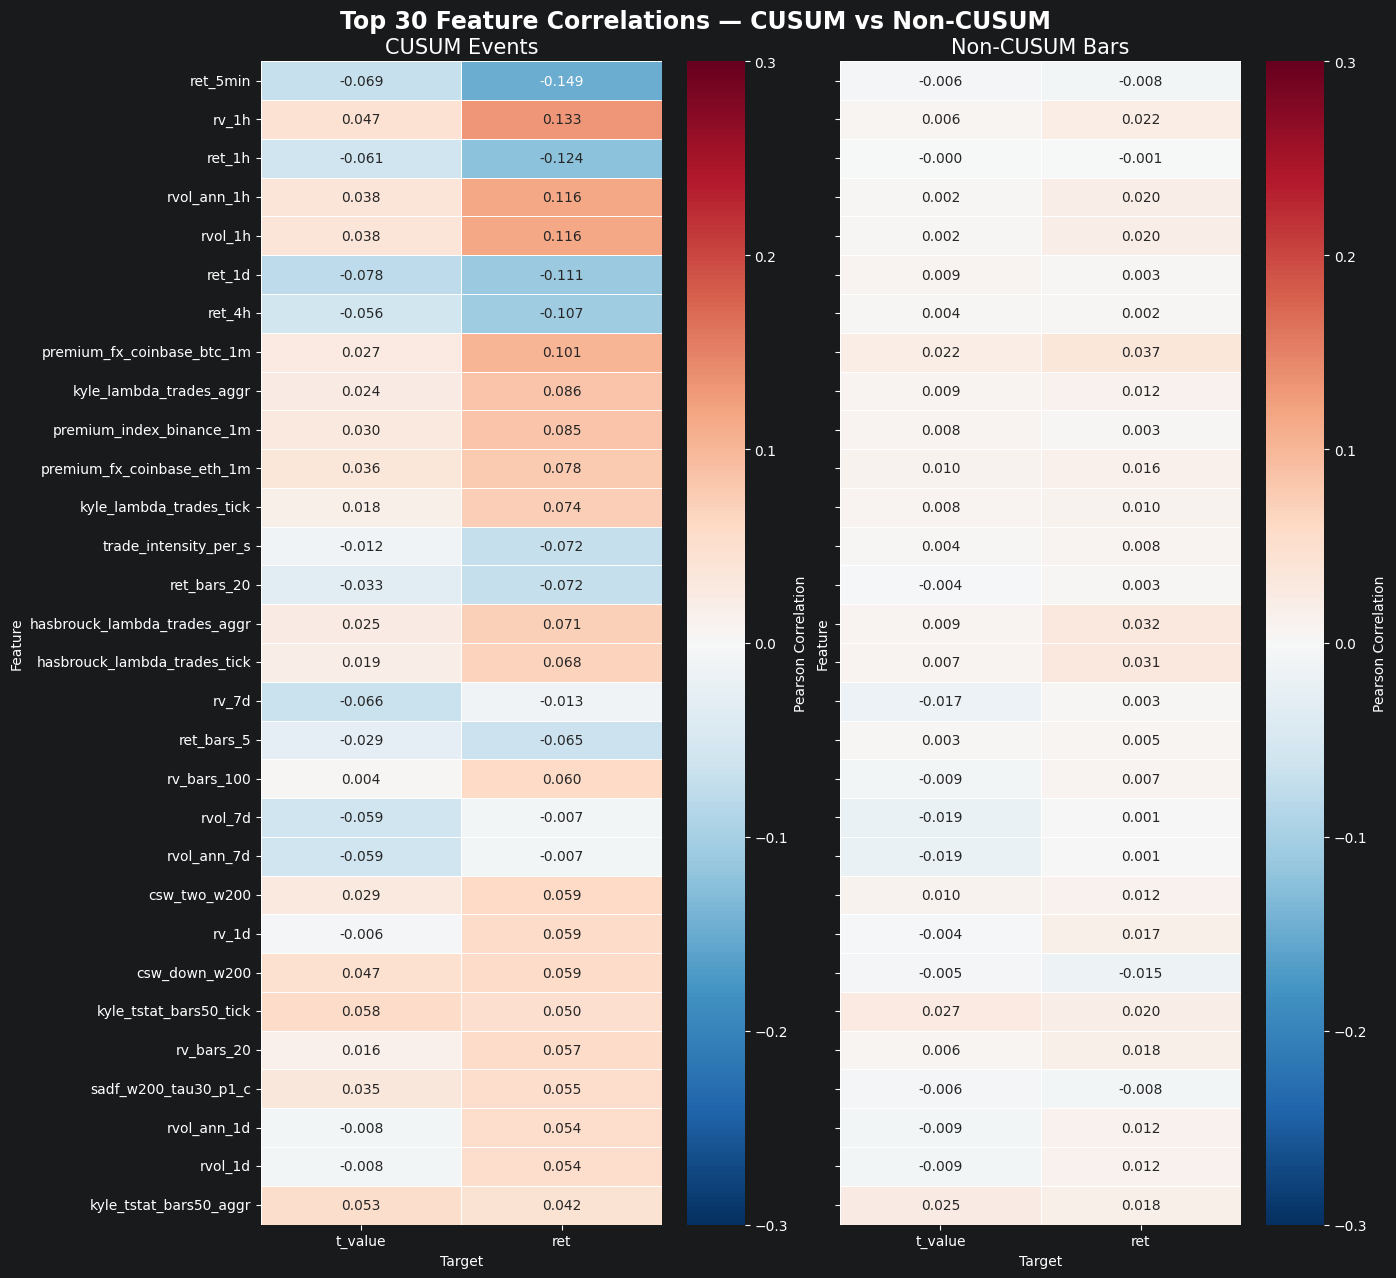

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 13),
    sharey=True
)

heatmaps = [
    (corr_cusum, "CUSUM Events"),
    (corr_non_cusum, "Non-CUSUM Bars")
]

for ax, (corr, title) in zip(axes, heatmaps):

    sns.heatmap(
        corr.loc[top_features, targets],
        annot=True,
        fmt=".3f",
        cmap="RdBu_r",
        center=0,
        vmin=-0.3,
        vmax=0.3,
        linewidths=0.4,
        ax=ax,
        cbar_kws={"label": "Pearson Correlation"}
    )

    ax.set_title(title, fontsize=15)
    ax.set_xlabel("Target")
    ax.set_ylabel("Feature")

fig.suptitle(
    "Top 30 Feature Correlations — CUSUM vs Non-CUSUM",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

## First Primary strategy

In [60]:
import numpy as np
import pandas as pd
from mlfinpy.filters import cusum_filter


def cusum_with_runs(close: pd.Series, threshold: float = 0.05) -> pd.DataFrame:
    """Aceeasi logica ca mlfinpy.cusum_filter, dar pastreaza si:
    - side: +1 (s_pos a declansat) / -1 (s_neg a declansat)
    - run_start: bara la care acumulatorul declansator a fost ultima data 0."""
    lr = np.log(close).diff().values
    s_pos = s_neg = 0.0
    pos_start = neg_start = 0
    rows = []
    for i in range(1, len(close)):
        s_pos = max(0.0, s_pos + lr[i])
        s_neg = min(0.0, s_neg + lr[i])
        if s_pos == 0.0:
            pos_start = i
        if s_neg == 0.0:
            neg_start = i
        if s_neg < -threshold:
            rows.append((close.index[i], -1, close.index[neg_start]))
            s_neg, neg_start = 0.0, i
        elif s_pos > threshold:
            rows.append((close.index[i], +1, close.index[pos_start]))
            s_pos, pos_start = 0.0, i
    ev = pd.DataFrame(rows, columns=["datetime", "side", "run_start"]).set_index("datetime")
    ev["run_hours"] = (ev.index.to_series() - ev["run_start"]).dt.total_seconds() / 3600
    return ev


cusum_events = cusum_filter(raw_time_series=df["close"], threshold=0.02)
ev = cusum_with_runs(df["close"], threshold=0.02)
assert ev.index.equals(cusum_events)  # aceleasi evenimente ca mlfinpy

# "rapid" = run mai scurt decat mediana ultimelor 100 de run-uri (doar trecut, fara lookahead)
ev["med_prev100"] = ev["run_hours"].shift(1).rolling(100, min_periods=30).median()
ev["fast"] = ev["run_hours"] < ev["med_prev100"]
0.01
cusum_df = df.loc[ev.index].join(ev[["side", "run_hours", "fast"]])

# Strategia 2 (L03_fast_dn_reversal): scadere de 5% mai rapida decat de obicei -> LONG
long_signals = cusum_df.index[
    (cusum_df["side"] == -1) &
    (cusum_df["fast"])
]

# Partea short nu a mers in niciun test -> fara semnale short
short_signals = cusum_df.index[[]]

print(f"LONG signals: {len(long_signals)}")
print(f"SHORT signals: {len(short_signals)}")

LONG signals: 5709
SHORT signals: 0


In [61]:
import numpy as np
import pandas as pd

# Construim evenimentele strategiei
long_df = df.loc[long_signals, ["ret", "t_value", "t1"]].copy()
long_df["strategy"] = "LONG"
long_df["side"] = 1

short_df = df.loc[short_signals, ["ret", "t_value", "t1"]].copy()
short_df["strategy"] = "SHORT"
short_df["side"] = -1

signals = pd.concat([long_df, short_df]).sort_index()
signals = signals.replace([np.inf, -np.inf], np.nan)
signals = signals.dropna(subset=["ret", "t_value"])

# Pozitiv = favorabil direcției semnalului
signals["directional_ret"] = signals["ret"] * signals["side"]
signals["directional_t"] = signals["t_value"] * signals["side"]

signals["win_ret"] = signals["directional_ret"] > 0
signals["win_trend"] = signals["directional_t"] > 0
signals["year"] = signals.index.year

def summarize(group):
    return pd.Series({
        "events": len(group),
        "mean_ret_%": group["directional_ret"].mean() * 100,
        "median_ret_%": group["directional_ret"].median() * 100,
        "win_rate_%": group["win_ret"].mean() * 100,
        "mean_directional_t": group["directional_t"].mean(),
        "median_directional_t": group["directional_t"].median(),
        "correct_trend_%": group["win_trend"].mean() * 100,
    })

print("=== OVERALL ===")
display(summarize(signals).to_frame().T.round(3))

print("=== LONG vs SHORT ===")
display(
    signals.groupby("strategy")
    .apply(summarize, include_groups=False)
    .round(3)
)

print("=== PERFORMANCE BY YEAR ===")
display(
    signals.groupby(["year", "strategy"])
    .apply(summarize, include_groups=False)
    .round(3)
)

=== OVERALL ===


,events,mean_ret_%,median_ret_%,win_rate_%,mean_directional_t,median_directional_t,correct_trend_%
0,5709.0,0.072,0.179,51.971,0.323,1.627,52.163


=== LONG vs SHORT ===


,events,mean_ret_%,median_ret_%,win_rate_%,mean_directional_t,median_directional_t,correct_trend_%
strategy,,,,,,,
LONG,5709.0,0.072,0.179,51.971,0.323,1.627,52.163


=== PERFORMANCE BY YEAR ===


,,events,mean_ret_%,median_ret_%,win_rate_%,mean_directional_t,median_directional_t,correct_trend_%
year,strategy,,,,,,,
2021,LONG,462.0,-0.002,-0.103,49.567,0.291,-0.904,49.784
2022,LONG,1738.0,0.023,-0.033,49.540,-0.146,-0.949,49.540
2023,LONG,595.0,0.156,0.315,55.966,1.227,2.643,57.479
2024,LONG,993.0,0.131,0.430,55.891,0.773,2.150,55.589
2025,LONG,1340.0,0.050,0.091,50.970,0.267,1.286,51.194
2026,LONG,581.0,0.140,0.225,52.668,0.182,1.441,52.840
